In [3]:
import sys
from pathlib import Path

# Add project root to sys.path so we can import from utils
project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

from utils.plotting import PALETTE, plot_pmf, set_style

# Apply standard style across all plots
set_style()

# Geometric Distribution: Modeling Waiting Times Until First Success

## 1. Intuition & Motivation

In previous notebooks, we asked: *"If I flip 10 coins, how many heads will I get?"* (Binomial).
Now we invert the question:
***"How many times do I have to flip a coin until I get my very first head?"***

- How many lottery tickets do you need to buy before winning?
- How many API requests must be sent before the first successful connection?
- How many resumes must a hiring manager screen until the first qualified hire?
- How many times must you roll a die before rolling a six?

The **Geometric distribution** models the number of independent Bernoulli trials needed to achieve the **first success**.

### A Note on the Two Conventions
In probability literature, there are two common definitions:
1. **Number of trials $k$ until first success**: $k \in \{1, 2, 3, \dots\}$ (at least 1 trial is required).
2. **Number of failures $y$ before first success**: $y \in \{0, 1, 2, \dots\}$ (where $y = k - 1$).

Throughout this notebook, we follow **Convention 1 ($k \ge 1$ trials)**, which is the standard implementation used by `scipy.stats.geom`.

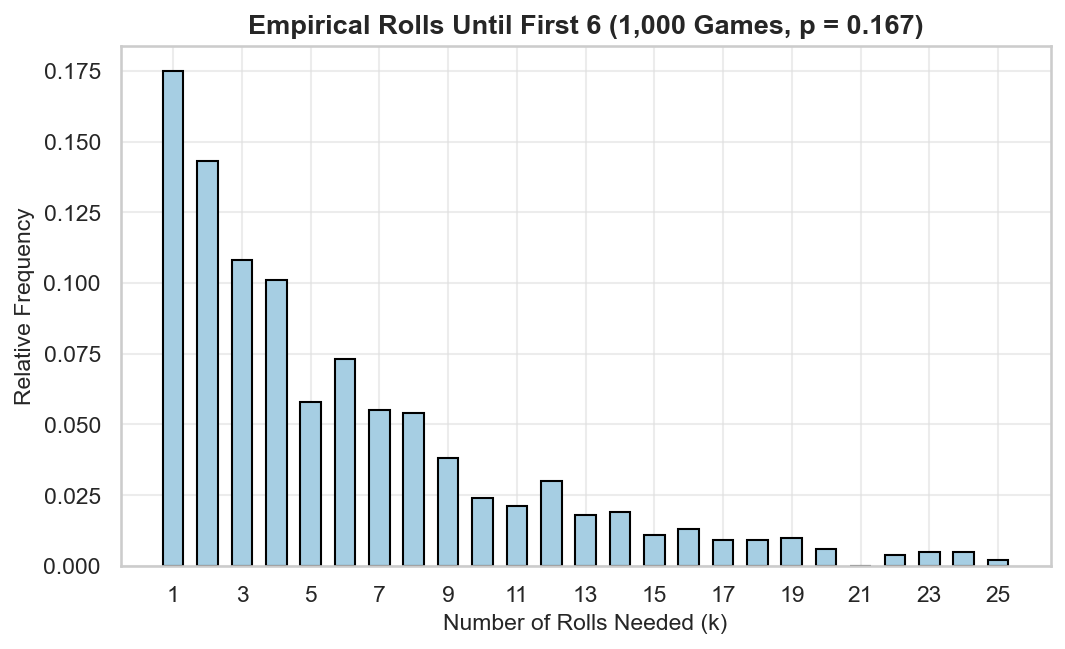

Sample Average Rolls to 1st Six: 6.07
Percentage of games won on Roll 1: 17.5%


In [5]:
# Probability of rolling a 6 on a fair die
p_six = 1 / 6
n_simulations = 1000

# Seed for reproducibility
rng = np.random.default_rng(seed=42)

# Simulate trials until first success for 1,000 experiments
# In numpy, geometric generates trials k in {1, 2, 3, ...}
rolls_until_six = rng.geometric(p=p_six, size=n_simulations)

# Plot empirical distribution
max_k = 25
counts, bins = np.histogram(rolls_until_six, bins=np.arange(0.5, max_k + 1.5, 1))

plt.figure(figsize=(8, 4.5))
plt.bar(
    np.arange(1, max_k + 1),
    counts / n_simulations,
    color=PALETTE["fill"],
    edgecolor="black",
    width=0.6,
)
plt.title(
    f"Empirical Rolls Until First 6 (1,000 Games, p = {p_six:.3f})", weight="bold"
)
plt.xlabel("Number of Rolls Needed (k)")
plt.ylabel("Relative Frequency")
plt.xticks(range(1, max_k + 1, 2))
plt.show()

print(f"Sample Average Rolls to 1st Six: {np.mean(rolls_until_six):.2f}")
print(f"Percentage of games won on Roll 1: {np.mean(rolls_until_six == 1) * 100:.1f}%")

## 2. Mathematical Definition

A discrete random variable $X$ follows a Geometric distribution with success parameter $p$, written:
$$X \sim \text{Geometric}(p)$$

### Parameter & Support
- **$p \in (0, 1]$**: Probability of success on each independent Bernoulli trial ($q = 1 - p$ is failure probability).
- **Support**: Infinite discrete positive integers: $k \in \{1, 2, 3, 4, \dots\}$.

### Probability Mass Function (PMF)
To succeed on trial $k$, the process must fail exactly $k - 1$ times in a row, and then succeed on the $k$-th trial:
$$P(X = k) = (1 - p)^{k - 1} p \quad \text{for } k = 1, 2, 3, \dots$$
Notice that each successive term is multiplied by $(1 - p)$. This is a **geometric progression**, which gives the distribution its name!

### Cumulative Distribution Function (CDF) & Survival Function
The probability that the first success occurs on or before trial $k$ is $1$ minus the probability that all first $k$ trials were failures:
$$F(k) = P(X \le k) = 1 - (1 - p)^k$$

The **Survival Function** (probability of needing *more* than $k$ trials) has an exceptionally clean closed form:
$$S(k) = P(X > k) = 1 - F(k) = (1 - p)^k$$


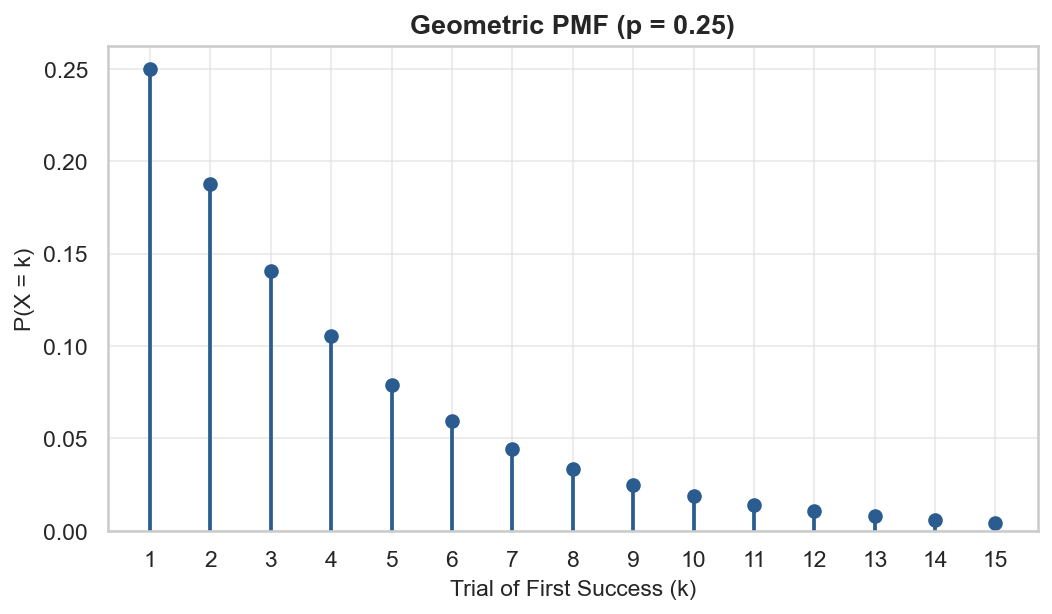

In [9]:
# Distribution parameter
p = 0.25
k_values = np.arange(1, 16)  # Show first 15 trials

# Exact theoretical PMF: P(X = k)
pmf_values = stats.geom.pmf(k_values, p)

# Plot PMF using our shared helper
fig, ax = plt.subplots(figsize=(8, 4.2))
plot_pmf(
    k_values,
    pmf_values,
    title=f"Geometric PMF (p = {p})",
    xlabel="Trial of First Success (k)",
    ylabel="P(X = k)",
    ax=ax,
)
ax.set_xticks(k_values)
plt.show()

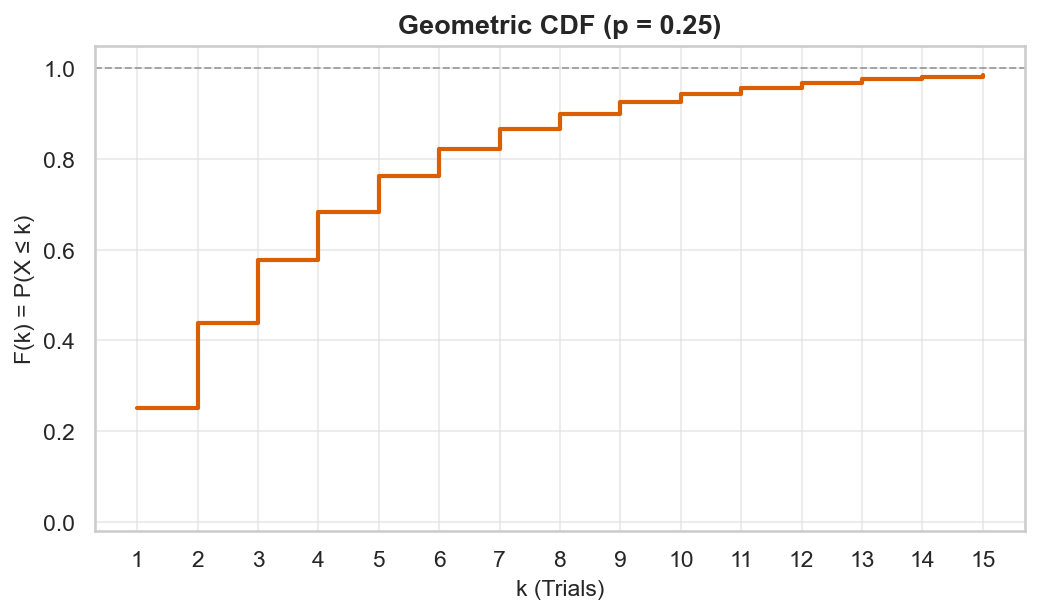

In [10]:
from utils.plotting import plot_cdf

# Exact theoretical CDF: P(X <= k) = 1 - (1 - p)^k
cdf_values = stats.geom.cdf(k_values, p)

fig, ax = plt.subplots(figsize=(8, 4.2))
plot_cdf(
    k_values,
    cdf_values,
    is_discrete=True,
    title=f"Geometric CDF (p = {p})",
    xlabel="k (Trials)",
    ylabel="F(k) = P(X ≤ k)",
    ax=ax,
)
ax.set_xticks(k_values)
plt.show()

## 3. Key Theoretical Properties

For $X \sim \text{Geometric}(p)$ (trials until first success, $k \ge 1$):

### 1. Expected Value (Mean): $\mathbb{E}[X] = \mu$
$$\mu = \frac{1}{p}$$
If an event has a $10\%$ chance ($p = 0.1$), on average you wait $1 / 0.1 = 10$ trials.

### 2. Variance & Standard Deviation: $\text{Var}(X) = \sigma^2$
$$\sigma^2 = \frac{1 - p}{p^2}, \quad \sigma = \frac{\sqrt{1 - p}}{p}$$

### 3. Skewness: $\gamma_1$
$$\gamma_1 = \frac{2 - p}{\sqrt{1 - p}}$$
Since $p \in (0, 1]$, skewness is **strictly positive** ($\gamma_1 > 0$). The Geometric distribution is *always* right-skewed.

### 4. Excess Kurtosis: $\gamma_2$
$$\gamma_2 = 6 + \frac{p^2}{1 - p}$$
Always greater than 6, indicating heavy tails.

### 5. The Memoryless Property (Crucial!)
The Geometric distribution is the **only discrete distribution** that is memoryless:
$$P(X > s + t \mid X > s) = P(X > t)$$
*Meaning:* If you have already rolled 5 failures, the probability that you need 3 more rolls is identical to starting fresh and needing 3 rolls. The process has no memory of past failures.


In [12]:
# Verify analytical moments against SciPy
p_test = 0.2

# Analytical formulas
mu_analytical = 1 / p_test
var_analytical = (1 - p_test) / (p_test**2)
std_analytical = np.sqrt(var_analytical)
skew_analytical = (2 - p_test) / np.sqrt(1 - p_test)
kurt_analytical = 6 + (p_test**2) / (1 - p_test)

# SciPy calculation
mu_sp, var_sp, skew_sp, kurt_sp = stats.geom.stats(p_test, moments="mvsk")

print("--- GEOMETRIC THEORETICAL MOMENTS ---")
print(f"Moment               | Analytical |   SciPy")
print("-" * 46)
print(f"Mean (μ)             | {mu_analytical:10.4f} | {float(mu_sp):10.4f}")
print(f"Variance (σ²)        | {var_analytical:10.4f} | {float(var_sp):10.4f}")
print(f"Std Deviation (σ)    | {std_analytical:10.4f} | {np.sqrt(float(var_sp)):10.4f}")
print(f"Skewness (γ₁)        | {skew_analytical:10.4f} | {float(skew_sp):10.4f}")
print(f"Excess Kurtosis (γ₂) | {kurt_analytical:10.4f} | {float(kurt_sp):10.4f}")

--- GEOMETRIC THEORETICAL MOMENTS ---
Moment               | Analytical |   SciPy
----------------------------------------------
Mean (μ)             |     5.0000 |     5.0000
Variance (σ²)        |    20.0000 |    20.0000
Std Deviation (σ)    |     4.4721 |     4.4721
Skewness (γ₁)        |     2.0125 |     2.0125
Excess Kurtosis (γ₂) |     6.0500 |     6.0500


In [13]:
# Demonstrating the Memoryless Property numerically
# P(X > s + t | X > s) == P(X > t)
s = 4  # already survived 4 failures
t = 3  # need at least 3 more trials

# Survival function: P(X > k) = (1 - p)^k
p_mem = 0.3
prob_s = (1 - p_mem) ** s
prob_s_plus_t = (1 - p_mem) ** (s + t)

# Conditional probability: P(A | B) = P(A and B) / P(B) = P(X > s+t) / P(X > s)
cond_prob = prob_s_plus_t / prob_s
uncond_prob = (1 - p_mem) ** t

print("--- MEMORYLESS PROPERTY VERIFICATION ---")
print(f"P(X > {s + t} | X > {s})  [Conditional]:   {cond_prob:.6f}")
print(f"P(X > {t})          [Unconditional]: {uncond_prob:.6f}")
print(f"Difference:                        {abs(cond_prob - uncond_prob):.1e}")

--- MEMORYLESS PROPERTY VERIFICATION ---
P(X > 7 | X > 4)  [Conditional]:   0.343000
P(X > 3)          [Unconditional]: 0.343000
Difference:                        0.0e+00


## 4. Parameter Variation

The single parameter $p$ governs the rate of geometric decay:
- **Small $p$ (e.g., $p = 0.05$ or $0.1$)**: Slow decay, large mean waiting time ($\mu = 10$ to $20$), very long tail.
- **Moderate $p$ (e.g., $p = 0.3$ or $0.5$)**: Moderate decay, mean waiting time $\mu = 2$ to $3.33$.
- **Large $p$ (e.g., $p = 0.8$)**: Extreme decay; vast majority of successes occur on trial 1 or 2 ($\mu = 1.25$).


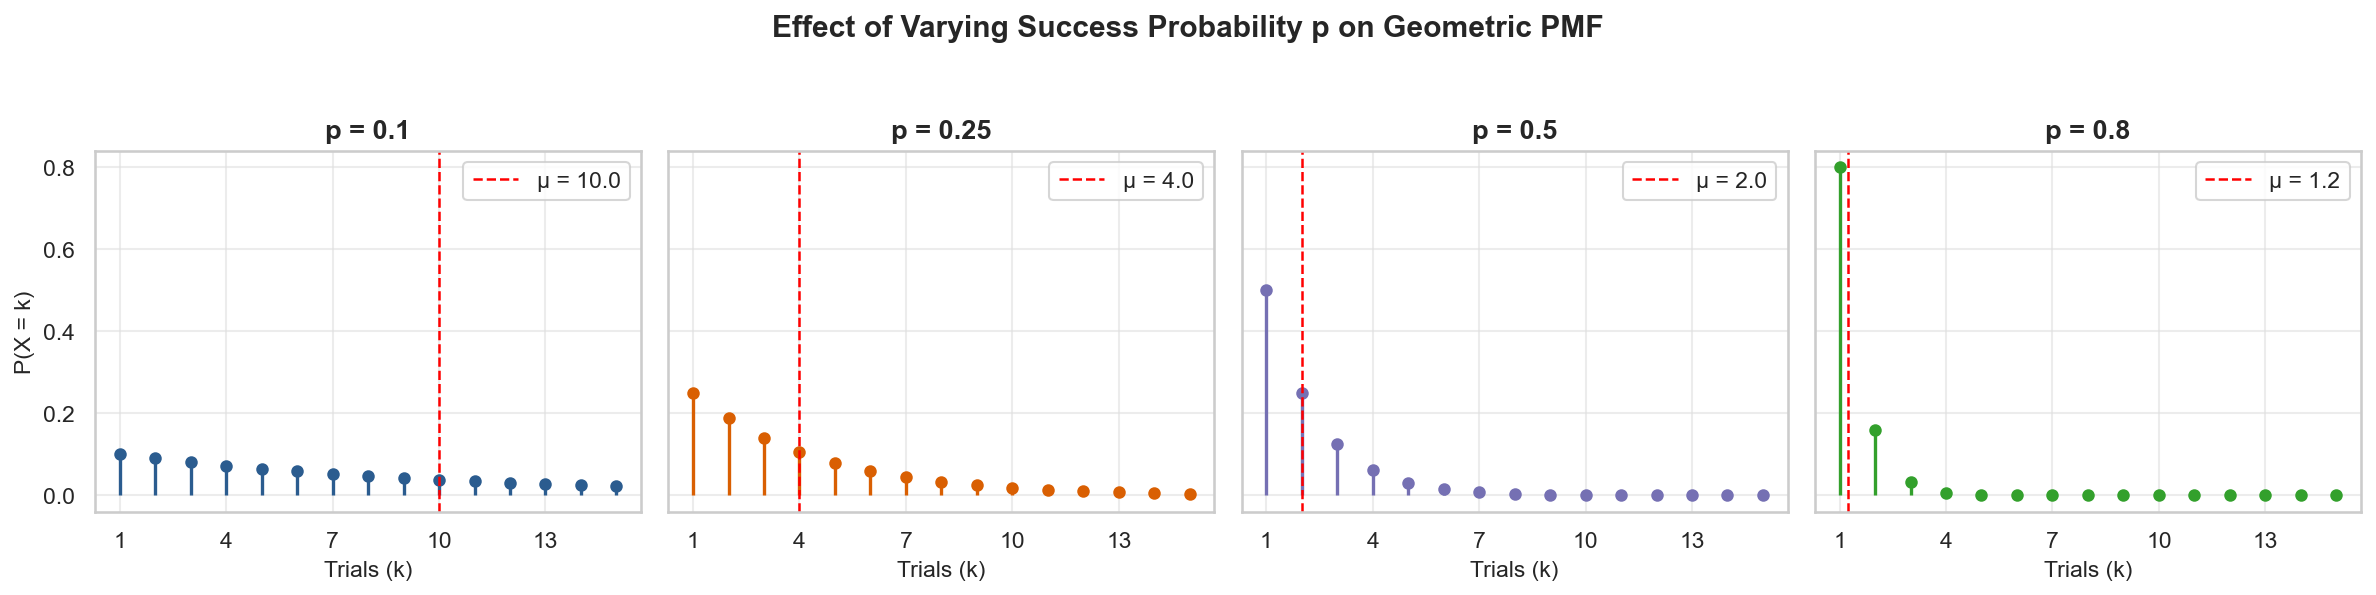

In [14]:
p_list = [0.1, 0.25, 0.5, 0.8]
colors = [
    PALETTE["primary"],
    PALETTE["secondary"],
    PALETTE["accent"],
    "#33a02c",
]
k_axis = np.arange(1, 16)

fig, axes = plt.subplots(1, 4, figsize=(16, 3.8), sharey=True)

for ax, p_val, col in zip(axes, p_list, colors):
    pmf = stats.geom.pmf(k_axis, p_val)
    markerline, stemlines, _ = ax.stem(k_axis, pmf, basefmt=" ")
    plt.setp(markerline, color=col, markersize=5)
    plt.setp(stemlines, color=col, linewidth=1.6)

    mu = 1 / p_val
    ax.axvline(
        mu, color="red", linestyle="--", linewidth=1.2, label=f"μ = {mu:.1f}"
    )
    ax.set_title(f"p = {p_val}")
    ax.set_xlabel("Trials (k)")
    ax.legend(frameon=True, loc="upper right")
    ax.set_xticks(range(1, 16, 3))

axes[0].set_ylabel("P(X = k)")
plt.suptitle(
    "Effect of Varying Success Probability p on Geometric PMF",
    y=1.04,
    weight="bold",
)
plt.tight_layout()
plt.show()

## 5. Simulation & Law of Large Numbers

When we simulate $N$ independent draws $X_1, X_2, \dots, X_N \sim \text{Geometric}(p)$:
The sample average represents the empirical average waiting time:
$$\bar{X}_N = \frac{1}{N} \sum_{i=1}^{N} X_i$$

By the Law of Large Numbers, $\bar{X}_N$ converges to the theoretical mean $\mu = \frac{1}{p}$ as $N \to \infty$.


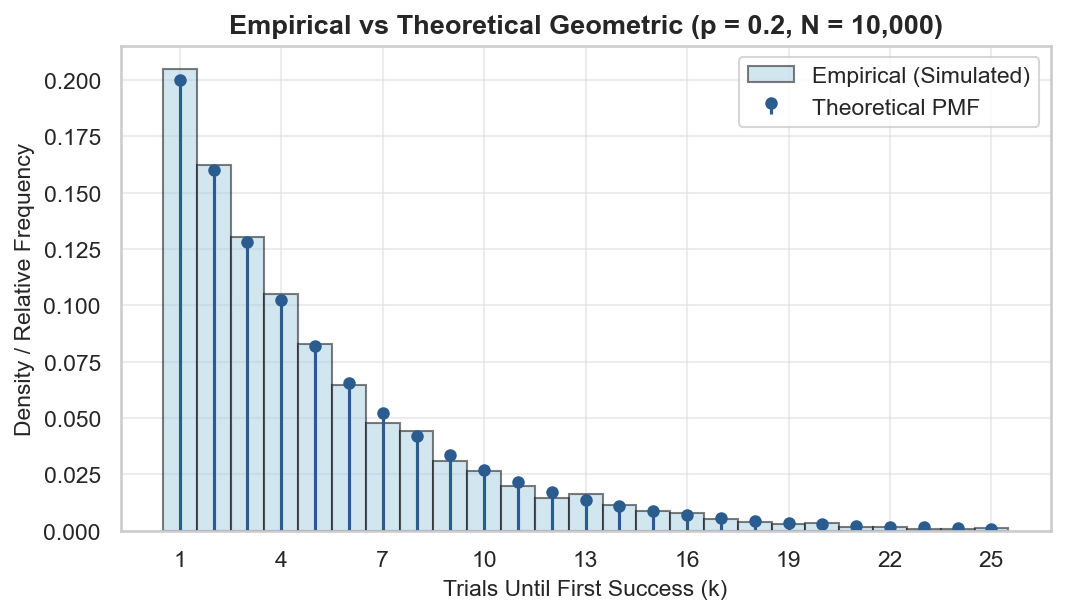

In [16]:
from utils.plotting import plot_sample_vs_theory

# Parameters
p_sim = 0.2
sample_size = 10000
k_max = 25

# Generate samples
samples_geom = stats.geom.rvs(p_sim, size=sample_size, random_state=42)

# Theoretical PMF
k_theory = np.arange(1, k_max + 1)
pmf_theory = stats.geom.pmf(k_theory, p_sim)

# Filter samples for cleaner visualization up to k_max
samples_plot = samples_geom[samples_geom <= k_max]

fig, ax = plt.subplots(figsize=(8, 4.2))
plot_sample_vs_theory(
    samples=samples_plot,
    x_theory=k_theory,
    y_theory=pmf_theory,
    is_discrete=True,
    title=f"Empirical vs Theoretical Geometric (p = {p_sim}, N = {sample_size:,})",
    xlabel="Trials Until First Success (k)",
    ax=ax,
)
ax.set_xticks(range(1, k_max + 1, 3))
plt.show()

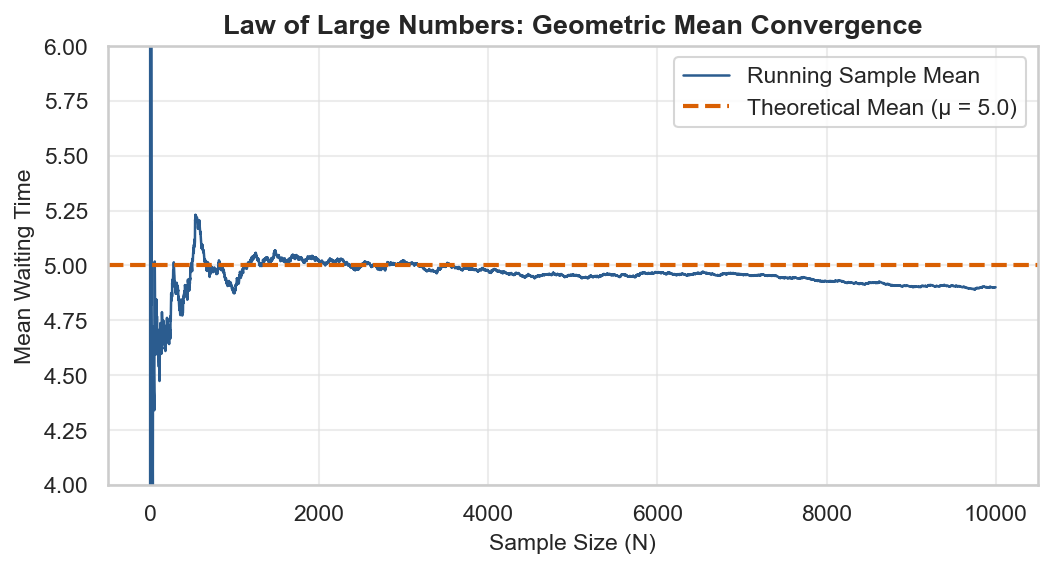

In [17]:
# Running average convergence
running_avg = np.cumsum(samples_geom) / np.arange(1, sample_size + 1)
mu_true = 1 / p_sim

plt.figure(figsize=(8, 3.8))
plt.plot(
    running_avg,
    color=PALETTE["primary"],
    linewidth=1.2,
    label="Running Sample Mean",
)
plt.axhline(
    mu_true,
    color=PALETTE["secondary"],
    linestyle="--",
    linewidth=2,
    label=f"Theoretical Mean (μ = {mu_true:.1f})",
)
plt.title("Law of Large Numbers: Geometric Mean Convergence")
plt.xlabel("Sample Size (N)")
plt.ylabel("Mean Waiting Time")
plt.ylim(mu_true - 1.0, mu_true + 1.0)
plt.legend(frameon=True)
plt.show()

## 6. Applied Real-World Use Case: Network Resilience & API Retry Strategy

### Scenario
A distributed microservice communicates with an external payment gateway over an unstable network.
- Each connection attempt has an independent success probability of **$p = 0.35$** (35%).
- A trial is an API connection attempt.
- The service needs to establish a connection before timing out.

### Engineering Questions:
1. What is the expected number of attempts required to connect?
2. What is the probability that the client connects within $k \le 4$ retries?
3. How many retries must the engineers configure to achieve a **99.9% Service Level Objective (SLO)**?
   $$P(X \le k) \ge 0.999 \implies 1 - (1 - p)^k \ge 0.999 \implies k \ge \frac{\ln(1 - 0.999)}{\ln(1 - p)}$$


In [18]:
p_api = 0.35
max_retries = 4

# Expected attempts
exp_attempts = 1 / p_api

# Probability of success within 4 attempts: CDF F(4)
prob_within_4 = stats.geom.cdf(max_retries, p_api)

# Calculate required retries for 99.9% SLO
target_slo = 0.999
required_retries = int(np.ceil(np.log(1 - target_slo) / np.log(1 - p_api)))

print("--- API RETRY RESILIENCE ANALYSIS ---")
print(f"Per-attempt success rate:        {p_api * 100:.1f}%")
print(f"Expected attempts to connect:    {exp_attempts:.2f}")
print(
    f"P(Success within {max_retries} attempts):      {prob_within_4 * 100:.2f}%"
)
print(f"P(Connection Timeout / Failure): {100 - prob_within_4 * 100:.2f}%\n")
print(f"Required attempts for {target_slo * 100:.1f}% SLO: {required_retries} retries")

--- API RETRY RESILIENCE ANALYSIS ---
Per-attempt success rate:        35.0%
Expected attempts to connect:    2.86
P(Success within 4 attempts):      82.15%
P(Connection Timeout / Failure): 17.85%

Required attempts for 99.9% SLO: 17 retries


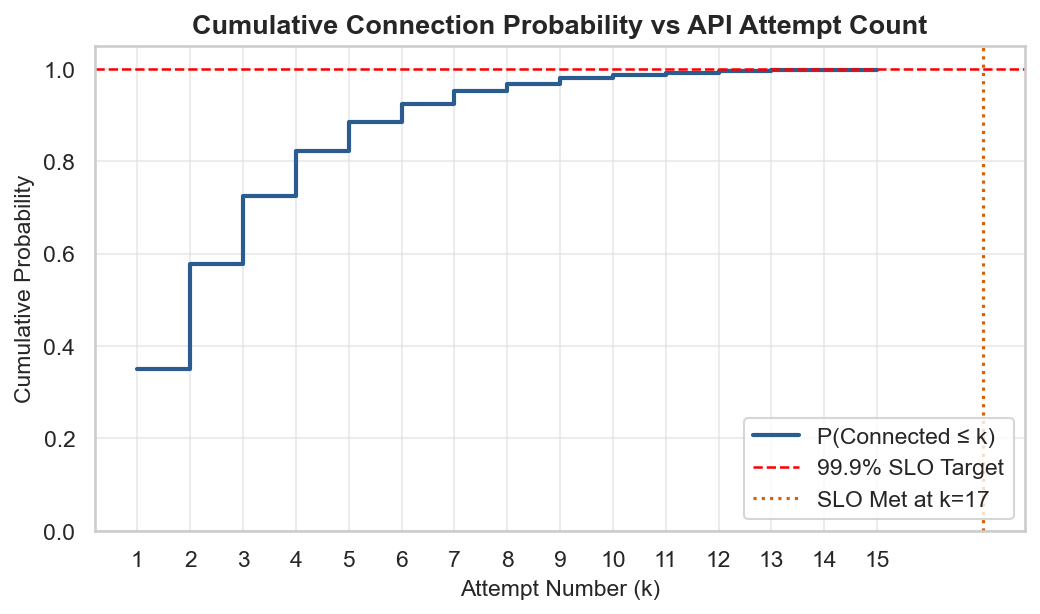

In [19]:
# Visualizing cumulative success vs retries
k_attempts = np.arange(1, 16)
cumulative_success = stats.geom.cdf(k_attempts, p_api)

plt.figure(figsize=(8, 4.2))
plt.step(
    k_attempts,
    cumulative_success,
    where="post",
    color=PALETTE["primary"],
    linewidth=2,
    label="P(Connected ≤ k)",
)
plt.axhline(
    0.999,
    color="red",
    linestyle="--",
    linewidth=1.2,
    label="99.9% SLO Target",
)
plt.axvline(
    required_retries,
    color=PALETTE["secondary"],
    linestyle=":",
    linewidth=1.5,
    label=f"SLO Met at k={required_retries}",
)

plt.title("Cumulative Connection Probability vs API Attempt Count")
plt.xlabel("Attempt Number (k)")
plt.ylabel("Cumulative Probability")
plt.xticks(k_attempts)
plt.ylim(0, 1.05)
plt.legend(frameon=True, loc="lower right")
plt.show()

## 7. Parameter Estimation (Maximum Likelihood Estimation - MLE)

Suppose we observe $N$ independent waiting times $k_1, k_2, \dots, k_N$ until first success. How do we estimate $p$?

### Likelihood Function
$$L(p) = \prod_{i=1}^{N} (1 - p)^{k_i - 1} p = p^N (1 - p)^{\sum_{i=1}^N k_i - N}$$

### Log-Likelihood & Optimization
$$\ln L(p) = N \ln(p) + \left(\sum_{i=1}^N k_i - N\right) \ln(1 - p)$$

Setting $\frac{d}{dp}\ln L(p) = 0$:
$$\frac{N}{p} - \frac{\sum k_i - N}{1 - p} = 0 \implies \hat{p}_{\text{MLE}} = \frac{N}{\sum_{i=1}^N k_i} = \frac{1}{\bar{k}}$$
The MLE of $p$ is simply **the reciprocal of the sample mean waiting time**!


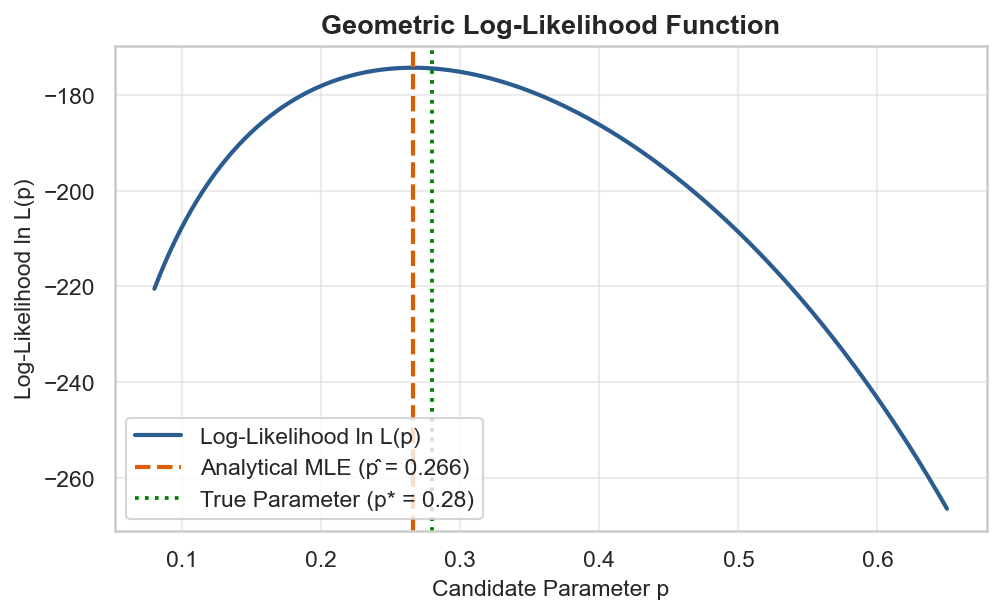

In [20]:
# True parameter
p_true = 0.28
N_obs = 80

# Generate observed waiting times
obs_data = stats.geom.rvs(p_true, size=N_obs, random_state=99)

# Analytical MLE: 1 / sample_mean
p_mle_analytical = 1 / np.mean(obs_data)


# Geometric log-likelihood function
def geom_log_lik(p_grid, data):
    n = len(data)
    sum_k = np.sum(data)
    return n * np.log(p_grid) + (sum_k - n) * np.log(1 - p_grid)


p_candidates = np.linspace(0.08, 0.65, 300)
log_lik = geom_log_lik(p_candidates, obs_data)

plt.figure(figsize=(7.5, 4.2))
plt.plot(
    p_candidates,
    log_lik,
    color=PALETTE["primary"],
    linewidth=2,
    label="Log-Likelihood ln L(p)",
)
plt.axvline(
    p_mle_analytical,
    color=PALETTE["secondary"],
    linestyle="--",
    linewidth=2,
    label=f"Analytical MLE (p̂ = {p_mle_analytical:.3f})",
)
plt.axvline(
    p_true,
    color="green",
    linestyle=":",
    linewidth=1.8,
    label=f"True Parameter (p* = {p_true:.2f})",
)

plt.title("Geometric Log-Likelihood Function")
plt.xlabel("Candidate Parameter p")
plt.ylabel("Log-Likelihood ln L(p)")
plt.legend(frameon=True)
plt.show()

In [21]:
from scipy.optimize import minimize


# Negative log-likelihood for optimizer
def neg_geom_log_lik(p, data):
    p_val = np.clip(p[0], 1e-5, 1 - 1e-5)
    return -np.sum(stats.geom.logpmf(data, p_val))


res = minimize(
    neg_geom_log_lik, x0=[0.5], args=(obs_data,), bounds=[(1e-4, 0.999)]
)
p_mle_num = res.x[0]

# Standard error via Fisher Information: SE = p * sqrt((1 - p) / N)
se_mle = p_mle_num * np.sqrt((1 - p_mle_num) / N_obs)
ci_lower = p_mle_num - 1.96 * se_mle
ci_upper = p_mle_num + 1.96 * se_mle

print("--- GEOMETRIC MLE ESTIMATION RESULTS ---")
print(f"True Parameter (p*):        {p_true:.4f}")
print(f"Sample Mean Waiting Time:   {np.mean(obs_data):.2f} trials")
print(f"Analytical MLE (1 / k̄):     {p_mle_analytical:.4f}")
print(f"Numerical MLE (Optimizer):  {p_mle_num:.4f}")
print(f"Standard Error (SE):        {se_mle:.4f}")
print(f"95% Confidence Interval:    [{ci_lower:.4f}, {ci_upper:.4f}]")

--- GEOMETRIC MLE ESTIMATION RESULTS ---
True Parameter (p*):        0.2800
Sample Mean Waiting Time:   3.76 trials
Analytical MLE (1 / k̄):     0.2658
Numerical MLE (Optimizer):  0.2658
Standard Error (SE):        0.0255
95% Confidence Interval:    [0.2159, 0.3157]


## 8. Related Distributions & Summary

The Geometric distribution connects directly to both discrete and continuous probability:

1. **Negative Binomial Distribution**:
   - The Geometric distribution models waiting for the **1st** success ($r = 1$).
   - The Negative Binomial models waiting for the **$r$-th** success: $\text{NegativeBinomial}(r=1, p) \equiv \text{Geometric}(p)$.

2. **Exponential Distribution (Continuous Analog)**:
   - The Geometric distribution is the discrete waiting time until an event.
   - The **Exponential distribution** is its continuous counterpart (waiting time along continuous real time).
   - Both are the **only distributions** in their respective domains to possess the **memoryless property**!

3. **Bernoulli Distribution**:
   - A Geometric variable is formed by observing a sequence of Bernoulli trials until the first outcome with $X = 1$.

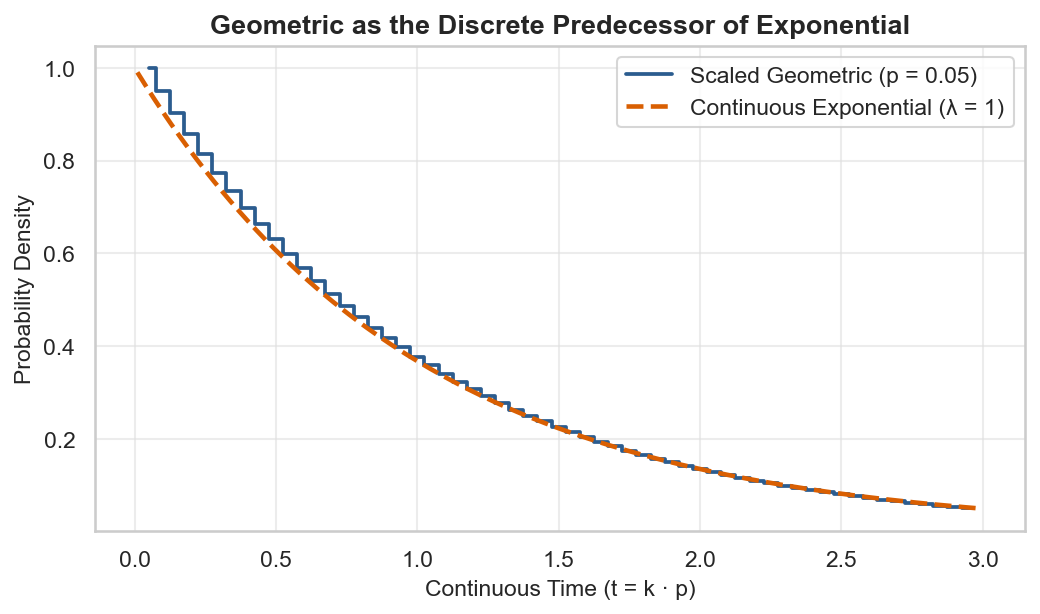

In [22]:
# Demonstrating Geometric convergence to Continuous Exponential
# As p -> 0 and time is scaled by delta_t = p, Geometric approaches Exponential(scale = 1/lambda)
fig, ax = plt.subplots(figsize=(8, 4.2))

# Discrete geometric scaled to continuous time: t = k * p
p_small = 0.05
k_steps = np.arange(1, 60)
t_discrete = k_steps * p_small
geom_pmf_scaled = stats.geom.pmf(k_steps, p_small) / p_small  # density scaling

ax.step(
    t_discrete,
    geom_pmf_scaled,
    where="mid",
    label=f"Scaled Geometric (p = {p_small})",
    color=PALETTE["primary"],
    linewidth=1.8,
)

# Continuous Exponential PDF with lambda = 1 (scale = 1)
t_continuous = np.linspace(0.01, 3.0, 200)
exp_pdf = stats.expon.pdf(t_continuous, scale=1.0)
ax.plot(
    t_continuous,
    exp_pdf,
    label="Continuous Exponential (λ = 1)",
    color=PALETTE["secondary"],
    linewidth=2.2,
    linestyle="--",
)

ax.set_title("Geometric as the Discrete Predecessor of Exponential")
ax.set_xlabel("Continuous Time (t = k · p)")
ax.set_ylabel("Probability Density")
ax.legend(frameon=True)
plt.show()

### Summary Card: Geometric Distribution

| Property | Formulation (Trials Convention, $k \ge 1$) |
| :--- | :--- |
| **Notation** | $X \sim \text{Geometric}(p)$ |
| **Parameter** | $p \in (0, 1]$ (success probability per trial) |
| **Support** | $k \in \{1, 2, 3, \dots\}$ |
| **PMF** | $P(X = k) = (1 - p)^{k - 1} p$ |
| **CDF** | $F(k) = 1 - (1 - p)^k$ |
| **Survival Function** | $S(k) = P(X > k) = (1 - p)^k$ |
| **Mean ($\mu$)** | $\frac{1}{p}$ |
| **Variance ($\sigma^2$)** | $\frac{1 - p}{p^2}$ |
| **Skewness ($\gamma_1$)** | $\frac{2 - p}{\sqrt{1 - p}}$ |
| **Memoryless Property** | $P(X > s + t \mid X > s) = P(X > t)$ |
| **MLE Estimator** | $\hat{p} = \frac{1}{\bar{k}}$ |
| **Continuous Analog** | Exponential distribution |
| **Key Use Cases** | Network retry backoff, marketing contact attempts, equipment failure inspections |